<a href="https://colab.research.google.com/github/Natt-8510/Inteligencia-Artificial/blob/main/3_CNN_Clasificaci%C3%B3n_de_d%C3%ADgitos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

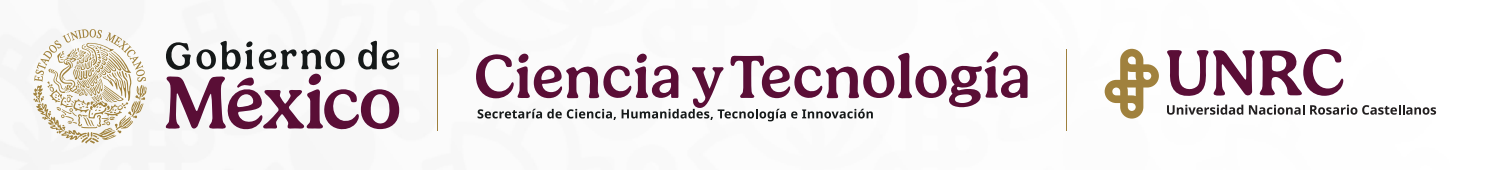

**Noviembre-2026**

**Natalia Rodríguez Flores**

# **Introducción**

Se cosntruye una red neuronal convolucional donde usaremos un CNN que es para clasificar dígitos que estan escritos a mano en un conjunto de datos MNIST, que es un problema de clasificación de imágenes.

Se toma la imágen del numero escrito a papel mediante una camara especializada para escanear y que se vea desde la computadora, la computadora va ir entrenando y aprendiendo como leer los dígitos que estan escritos a mano.

# **Desarrollo**

In [1]:
from sklearn.datasets import load_digits

digits = load_digits()

* Cargamos el conjunto de datos MNIST donde tenemos dígitos escritos a mano.

*¿Qué significa MNIST?*

También conocido como *"Hello world"* de la visión artificial. Contiene un conjunto de entrenamiento del 60.000 imágenes de dígitos escritos a mano (del 0 al 9). Y contiene otro conjunto de pruebas con 10.000 muestras adicionales.

In [2]:
digits.keys()

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])

* En la celda podemos observar lo que puede conetener el dataset.

In [3]:
print(digits.DESCR)

.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each block. This generates
an in

* Imprimimos la descripción para obtener la información del conjunto de datos.

## Visualización de una imagen

In [4]:
index = 0

* Accedemos desde el indice 0 que el 0 sirve para **obtener, modificar o eliminar el primer elemento** de una lista.

In [5]:
image = digits.images[index]
label = digits.target[index]

* Obtenemos la imagen del dígito y su etiqueta.

In [6]:
print(image)

[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


* Imprimimos la imagen.

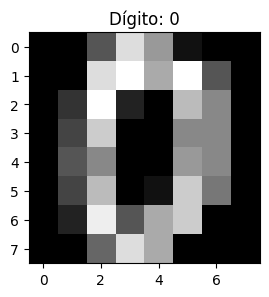

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(3, 3))
plt.imshow(image, cmap=plt.cm.gray)
plt.title(f'Dígito: {label}')
plt.show()

* Con ayuda de *"Matplotlip"* se puede mostrar la imagen.

## Preprocesamiento de datos

In [8]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target,
    test_size=0.2, random_state=42
)

# One-hot encode the target variable
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

* Separa los datos en conjuntos de entrenamiento y prueba, donde el "*train_test_split"* reserva el 20% de prueba y *"test_size=0.2"* es el 80%.

In [9]:
print(X_train.shape)
print(X_test.shape)

(1437, 64)
(360, 64)


* Nos muestra la longitud de entrenamiento y prueba.

In [10]:
reshaped_tensor = tf.reshape(X_train[0], shape=(8, 8))
print(reshaped_tensor)

tf.Tensor(
[[ 0.  0.  3. 14.  1.  0.  0.  0.]
 [ 0.  0. 12. 12.  0.  0.  0.  0.]
 [ 0.  3. 16.  6.  0.  0.  0.  0.]
 [ 0.  5. 16.  2.  0.  0.  0.  0.]
 [ 0.  6. 16.  2.  5.  2.  0.  0.]
 [ 0.  4. 16.  2. 12. 15.  2.  0.]
 [ 0.  1. 14. 13.  2. 13. 11.  0.]
 [ 0.  0.  3. 11. 16. 13.  4.  0.]], shape=(8, 8), dtype=float64)


* Imprimimos el tensor, pero se muestra como una matriz.

In [11]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Normalizar los datos
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

* Usamos *"StandardScaler"* cuando las características de entrada tienen distribuciones y varianzas diferentes.

Como dato extra el *"StandardScaler"* es quien elimina la media y se escalan los datos a varianza unitaria.

Mientras tanto *"MinMaxScaler"* reescala el cojunto de datos de manera que todos los valores de las características estén dentro de un rango específico.

Ambos *"StandardScaler"* son *"MinMaxScaler"* muy sensbles a la presencia de valores atípicos.

In [12]:
reshaped_tensor = tf.reshape(X_train[0], shape=(8, 8))
# Redondeamos para tener una mejor visualizacion
reshaped_tensor =  tf.floor(reshaped_tensor * 100) / 100
print(reshaped_tensor)

tf.Tensor(
[[ 0.   -0.35 -0.47  0.5  -2.55 -1.04 -0.41 -0.14]
 [-0.07 -0.62  0.3   0.   -2.19 -1.36 -0.53 -0.14]
 [-0.05  0.12  1.08 -0.2  -1.17 -1.28 -0.56 -0.12]
 [-0.04  0.86  1.13 -1.17 -1.61 -1.29 -0.63 -0.05]
 [ 0.    1.09  1.34 -1.13 -0.91 -1.14 -0.82  0.  ]
 [-0.07  0.82  1.39 -0.83  0.69  1.17 -0.34 -0.1 ]
 [-0.04  0.15  1.14  0.64 -1.43  0.68  1.47 -0.22]
 [-0.03 -0.31 -0.5  -0.25  0.84  1.05  0.45 -0.2 ]], shape=(8, 8), dtype=float64)


In [13]:
# Redimensionar el tensor a la forma (total, 8, 8)
X_train = tf.reshape(X_train, (X_train.shape[0], 8, 8))
X_test = tf.reshape(X_test, (X_test.shape[0], 8, 8))

* Usamos *"tf.reshape"* para convertir los datos de entrada, en matrices de 8x8 píxeles.

Nota: generalmente usamos *"tf.reshape"* para cambiar o dividir ejes adyacentes.

## Red neuronal convolucional

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D

# Crear el modelo de CNN
model = Sequential([
    Conv2D(32, kernel_size=(3, 3),
        activation='relu',
        input_shape=(8, 8, 1)
    ),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


* Usamos un modelo secuencial de *"Keras"*, que es una pila lineal de capas.

Nota: Keras es una biblioteca de alto nivel para el aprendizaje profundo esto para contruir redes neuronales mediante enfoques secuenciales.

## Compilar el modelo

In [ ]:
from tensorflow.keras.optimizers import Adam

# Tasa de aprendizaje deseada
learning_rate = 0.001
adam_optimizer = Adam(learning_rate=learning_rate)

* Ponemos un optimizador que es Adam con una tasa de aprendizaje del 0.001

In [15]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

* Compilamos el modelo utilizando el optimizador Adam y la función de pérdida de entropía cruzada categóricamente dispersa, para la clasificación.

## Entrenar el modelo

In [16]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.6397 - loss: 1.5310 - val_accuracy: 0.8889 - val_loss: 0.8219
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9243 - loss: 0.4796 - val_accuracy: 0.9132 - val_loss: 0.4227
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9530 - loss: 0.2361 - val_accuracy: 0.9167 - val_loss: 0.2804
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9721 - loss: 0.1560 - val_accuracy: 0.9236 - val_loss: 0.2214
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9809 - loss: 0.1127 - val_accuracy: 0.9410 - val_loss: 0.1749
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9800 - loss: 0.0852 - val_accuracy: 0.9410 - val_loss: 0.1724
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9861 - loss: 0.0691 - val_accuracy: 0.9514 - val_loss: 0.1484
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9896 - loss: 0.0533 - val_accuracy: 0.9514 - val_lo

* Entrenamos el modelo con diez epocas. El método *"fit"* procesa los datos en lotes de 32 (*batch_size*) durante las diez épocas completas. usa el 20% de los datos de entrenamiento (*validation_split=0.2*) para validar el rendimiento en cada época.

## Función de pérdida

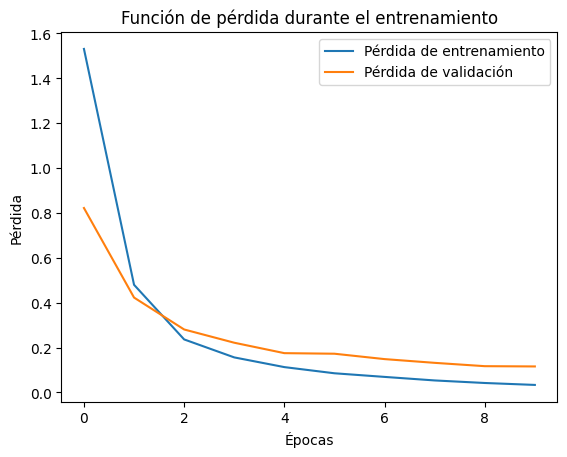

In [17]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Pérdida de entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.title('Función de pérdida durante el entrenamiento')
plt.show()


* Podemos observar que la funcion de la pérdida va hacia abajo, eso es bueno dentro de nuestro modelo.

## Evaluación

In [18]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f'Loss: {loss}, Accuracy: {accuracy}')

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9806 - loss: 0.0681  
Loss: 0.06805288791656494, Accuracy: 0.980555534362793


* El modelo *"evaluate"* calcula la pérdida y la precisión en el conjunto de prueba (X_test, y_test), proporcionando una métrica objetiva de la capacidad de generalización del modelo.

In [19]:
import numpy as np
from sklearn.metrics import confusion_matrix, recall_score

y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
# Convert y_test back to multiclass format
y_test_classes = np.argmax(y_test, axis=1)

conf_matrix = confusion_matrix(y_test_classes, y_pred_classes)
sensitivity = recall_score(y_test_classes, y_pred_classes, average=None)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


* En la parte de *"predict"* es donde genera las probabilidades y *"np.argmax"* convierte esas posibilidades y las etiqueta one-hot de vuelta a clases numéricas.

Después tenemos *"confusion_matrix"* muestra cuántas veces se confundió una clase con otra, mientras que el *"recall_score"* calcula la sensibilidad.

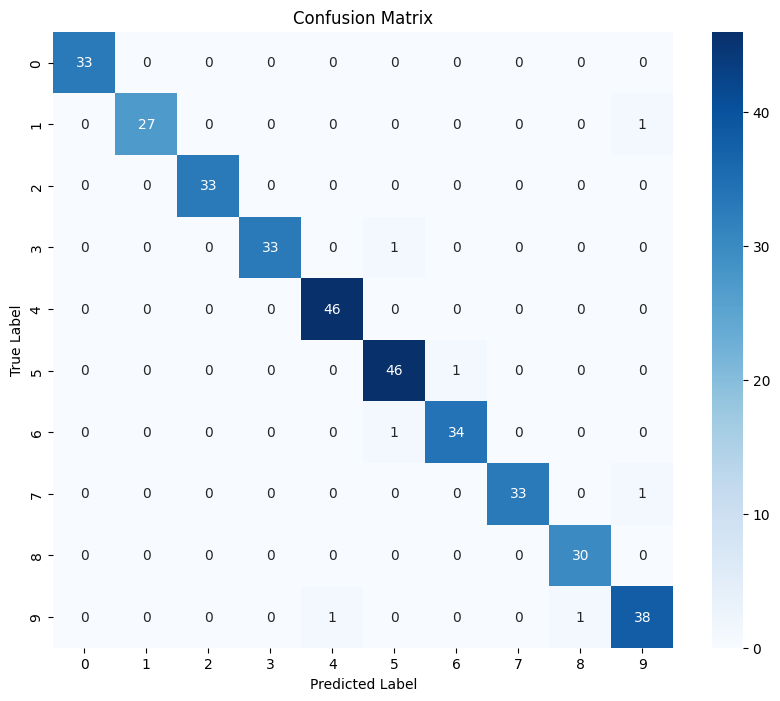

Sensitivity (Recall) for each class:
Class 0: 1.0
Class 1: 0.9642857142857143
Class 2: 1.0
Class 3: 0.9705882352941176
Class 4: 1.0
Class 5: 0.9787234042553191
Class 6: 0.9714285714285714
Class 7: 0.9705882352941176
Class 8: 1.0
Class 9: 0.95


In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# Visualizar la matriz de confusión como una imagen de colores
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Mostrar la sensibilidad (recall) para cada clase
print('Sensitivity (Recall) for each class:')
for i in range(10):
    print(f'Class {i}: {sensitivity[i]}')

* Podemos observar una matriz de confusión como es la imagen de colores.

El recall nos dice que tan efectivo es el modelo para encontrar todas las instancias positivas en comparación con el total de instancias positivas.

## Bonus

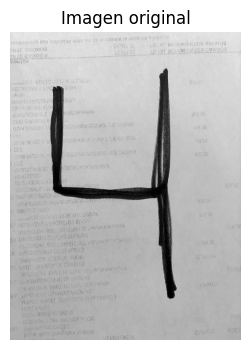

In [21]:
from PIL import Image
import matplotlib.pyplot as plt

# Cambia por el nombre de tu archivo
ruta = "/content/mi_numero.png"
# Escala de grises ("L")
img = Image.open(ruta).convert("L")

# mostrar la imagen
plt.figure(figsize=(4, 4))
plt.imshow(img, cmap="gray")
plt.title("Imagen original")
plt.axis("off")
plt.show()

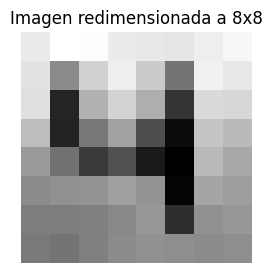

In [22]:
import matplotlib.pyplot as plt

# redimensionar a 8x8
img_resized = img.resize((8, 8), Image.Resampling.LANCZOS)

# mostrar imagen
plt.figure(figsize=(3, 3))
plt.imshow(img_resized, cmap="gray")
plt.title("Imagen redimensionada a 8x8")
plt.axis("off")
plt.show()

# opcional, guardamos la imagen si es necesario
img_resized.save("imagen_8x8.png")

## Preprocesamiento

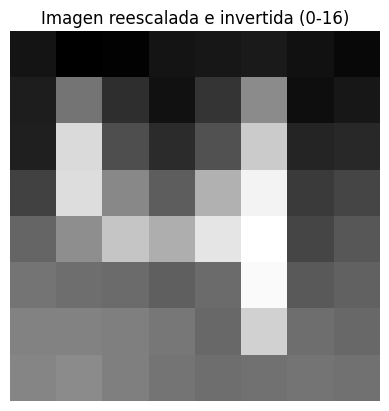

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# reescalar de 0-255 a 0-16 e invertir (fondo negro = 0)
img_array = np.array(img_resized).astype("float32")
img_array = 16 - (img_array / 255 * 16)

# mostrar imagen
plt.imshow(img_array, cmap="gray")
plt.title("Imagen reescalada e invertida (0-16)")
plt.axis("off")
plt.show()

* Rescalamos los valores de la imagen por los valores utilizados por las imagenes de la base de datos de MNIST, en otras palabras, la imagen debe de tener valores de entre 0 y 16.

In [24]:
from sklearn.preprocessing import StandardScaler

# normalizar
scaler = StandardScaler()
img_flat = img_array
img_scaled = scaler.fit_transform(img_flat)

# Dar forma (1,8,8) que es el input del modelo
img_tensor = img_scaled.reshape(1, 8, 8)

* En esta celda se estandariza la imagen.

## Evaluación

In [25]:
pred = model.predict(img_tensor)
digit = np.argmax(pred)
print("Predicción:", digit)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Predicción: 4


# **Referencias**

### Referencias Bibliográficas (APA 7)

- Databricks. (s.f.). *¿Qué es un modelo de Keras?* https://www.databricks.com/es/blog/what-is-keras-model
- Development Seed. (s.f.). *Lesson 3: Intro to tensors, functions, and datasets*. https://developmentseed.org/tensorflow-eo-training-2/docs/Lesson3_Intro_tensors_functions_datasets.html
- Interactive Chaos. (s.f.). *El dataset MNIST*. https://interactivechaos.com/es/manual/tutorial-de-deep-learning/el-dataset-mnist
- Scikit-learn. (s.f.). *Compare the effects of different scalers on data with outliers*. https://scikit-learn.org/stable/auto_examples/preprocessing/plot_all_scaling.html